In [1]:
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import glob
from PIL import Image
from pathlib import Path
from skytrack.visdrone import load_annotations, draw_boxes

ROOT = Path.cwd().parent                       # the SkyTrack folder
VAL_DIR = ROOT / "data/raw/VisDrone2019-DET-val"
IMG_DIR = VAL_DIR / "images"
ANN_DIR = VAL_DIR / "annotations"
frames_df = load_annotations(VAL_DIR/ANN_DIR, VAL_DIR/IMG_DIR)
print(frames_df.image)

0        0000327_03601_d_0000729
1        0000327_03601_d_0000729
2        0000327_03601_d_0000729
3        0000327_03601_d_0000729
4        0000327_03601_d_0000729
                  ...           
40164    0000276_02401_d_0000519
40165    0000276_02401_d_0000519
40166    0000276_02401_d_0000519
40167    0000276_02401_d_0000519
40168    0000276_02401_d_0000519
Name: image, Length: 40169, dtype: str


In [2]:


img_data = cv2.imread(str(IMG_DIR / "0000327_03601_d_0000729.jpg"))
annotation = np.loadtxt(ANN_DIR/'0000327_03601_d_0000729.txt', delimiter=",")
name = "0000327_03601_d_0000729"
one = frames_df[frames_df["image"] == name].copy()
one["x_center"] = (one["x"] + one["w"]/2) / one["img_w"]
one["width"] = (one["w"] / one["img_w"])
one["y_center"] = (one["y"] + one["h"]/2) / one["img_h"]
one["height"] = (one["h"]/ one["img_h"])
print(one[["x_center", "y_center", "width", "height"]].describe())


        x_center   y_center      width     height
count  64.000000  64.000000  64.000000  64.000000
mean    0.472088   0.349285   0.023702   0.036601
std     0.110333   0.212945   0.021151   0.029113
min     0.201103   0.054248   0.005147   0.014379
25%     0.396507   0.184641   0.011765   0.023203
50%     0.459375   0.302288   0.015441   0.028105
75%     0.533640   0.470752   0.025368   0.041176
max     0.707721   0.960131   0.120588   0.219608


In [3]:
before = len(frames_df)
clean = frames_df[(frames_df["score"] == 1) & (frames_df["category"].between(1, 10))].copy()
print("Rule 1 removed", before - len(clean))
print(len(clean))

Rule 1 removed 1410
38759


In [4]:
clean["cls"] = clean["category"] - 1
print(len(clean))
print(clean.groupby(["cls", "name"]).size())

38759
cls  name           
0    pedestrian          8844
1    people              5125
2    bicycle             1287
3    car                14064
4    van                 1975
5    truck                750
6    tricycle            1045
7    awning-tricycle      532
8    bus                  251
9    motor               4886
dtype: int64


In [5]:
#Checking how many boxes extend past the image edge
outside = (
    (clean["x"] < 0) |
    (clean["y"] < 0) |
    (clean["x"] + clean["w"] > clean["img_w"])|
     (clean["y"] + clean["h"] > clean["img_h"])
)
print(outside.sum())

0


In [6]:
two_small = (           # "too small": w or h under 2 px
    (clean["w"] < 2) |
    (clean["h"] < 2)
)
small = (           #w or h under 2 px
    (clean["w"] == 2) |
    (clean["h"] == 2)
)
print(two_small.sum())
print(small.sum())
print(clean[["w", "h"]].min())

0
48
w    2
h    2
dtype: int64


In [7]:
#Checking the ignored regions proportions to entire image size
ign = frames_df[frames_df["category"] == 0].copy()
ign["area_frac"] = (ign["w"] * ign["h"]) / (ign["img_w"] * ign["img_h"])
per_image = ign.groupby("image")["area_frac"].sum()
print(per_image.describe())
print(len(per_image), "of", frames_df["image"].nunique(), "images have ignored regions")

count    340.000000
mean       0.017544
std        0.028105
min        0.000173
25%        0.002296
50%        0.007252
75%        0.020957
max        0.261633
Name: area_frac, dtype: float64
340 of 548 images have ignored regions


In [8]:
print((per_image > 0.05).sum(), "images over 5% ignored")
print((per_image > 0.10).sum(), "images over 10% ignored")

35 images over 5% ignored
7 images over 10% ignored


In [9]:
def convert_split(src_dir, dst_dir):
    """Convert one VisDrone split to YOLO format: painted images + label files."""
    src_dir, dst_dir = Path(src_dir), Path(dst_dir) 
    src_img_dir = src_dir / "images"    
    src_ann_dir = src_dir / "annotations"
    out_img_dir = dst_dir / "images"
    out_lbl_dir = dst_dir / "labels"
    out_img_dir.mkdir(parents=True, exist_ok=True)
    out_lbl_dir.mkdir(parents=True, exist_ok=True)

    df = load_annotations(src_ann_dir, src_img_dir)
    counts = {"images": df["image"].nunique(), "raw_rows": len(df)} 

    # Rule 5 rows (painted later), taken before filtering removes them
    ignored = df[df["category"] == 0]

    # Rule 1: real objects only
    clean_df = df[(df["score"] == 1) & (df["category"].between(1, 10))].copy()
    counts["rule1_removed"] = len(df) - len(clean_df)

    # Rule 3: clip boxes to the image (work with corners, then rebuild w and h)
    x1 = clean_df["x"].clip(lower=0)
    y1 = clean_df["y"].clip(lower=0)
    x2 = (clean_df["x"] + clean_df["w"]).clip(upper=clean_df["img_w"])
    y2 = (clean_df["y"] + clean_df["h"]).clip(upper=clean_df["img_h"])
    counts["rule3_clipped"] = int((
        (x1 != clean_df["x"]) | (y1 != clean_df["y"]) |
        (x2 != clean_df["x"] + clean_df["w"]) | (y2 != clean_df["y"] + clean_df["h"])
    ).sum())
    clean_df["x"], clean_df["y"] = x1, y1
    clean_df["w"], clean_df["h"] = x2 - x1, y2 - y1

    # Rule 4: drop boxes under 2 px (after clipping, so cut-off boxes get caught)
    before = len(clean_df)
    clean_df = clean_df[(clean_df["w"] >= 2) & (clean_df["h"] >= 2)].copy()
    counts["rule4_removed"] = before - len(clean_df)

    # Rule 2 + YOLO conversion
    clean_df["cls"] = clean_df["category"] - 1
    clean_df["x_center"] = (clean_df["x"] + clean_df["w"] / 2) / clean_df["img_w"]
    clean_df["y_center"] = (clean_df["y"] + clean_df["h"] / 2) / clean_df["img_h"]
    clean_df["width"] = clean_df["w"] / clean_df["img_w"]
    clean_df["height"] = clean_df["h"] / clean_df["img_h"]
    yolo_cols = ["cls", "x_center", "y_center", "width", "height"]

    # Per image: paint, save the image, write the labels
    for stem in df["image"].unique():
        img_path = src_img_dir / f"{stem}.jpg"
        img = cv2.imread(str(img_path))
        if img is None:
            raise FileNotFoundError(img_path)

        img_ignored = ignored[ignored["image"] == stem]
        img_kept = clean_df[clean_df["image"] == stem]

        # Rule 5: paint ignored regions gray
        for row in img_ignored.itertuples():
            x, y = max(int(row.x), 0), max(int(row.y), 0)
            x2, y2 = int(row.x + row.w), int(row.y + row.h)
            img[y:y2, x:x2] = 114

        cv2.imwrite(str(out_img_dir / f"{stem}.jpg"), img)
        img_kept[yolo_cols].to_csv(out_lbl_dir / f"{stem}.txt", sep=" ",
                                   header=False, index=False, float_format="%.6f")

    counts["boxes_kept"] = len(clean_df)
    return counts

counts = convert_split(VAL_DIR, ROOT / "data/yolo/val")
print(counts)

{'images': 548, 'raw_rows': 40169, 'rule1_removed': 1410, 'rule3_clipped': 0, 'rule4_removed': 0, 'boxes_kept': 38759}


- 1378 (category 0) + 32(category 11) 
- 38759 total objects 

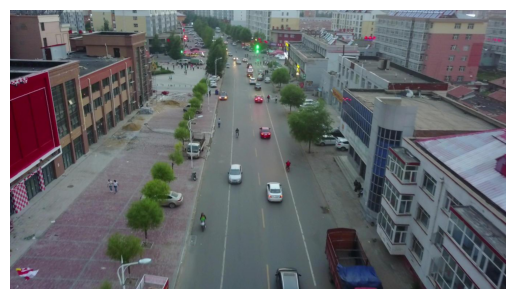

In [10]:
img_rgb = cv2.cvtColor(img_data, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.axis("off")
plt.show()

In [11]:
from skytrack.visdrone import convert_split
counts = convert_split(ROOT / "data/raw/VisDrone2019-DET-train", ROOT / "data/yolo/train")
print(counts)

{'images': 6471, 'raw_rows': 353550, 'rule1_removed': 10345, 'rule3_clipped': 0, 'rule4_removed': 8, 'boxes_kept': 343197}
